## 1. Summary

This project explored whether machine learning can help assess agricultural mechanization prices by predicting regional reference prices and comparing them with farmers' quoted prices.

Three regression models were evaluated using 3.505 historical records and four input features: equipment type, manufacturer, model specifications and the farmer's quoted price.

Ridge Regression achieved the best overall results, with an MAE of 377,28 EUR and an R² of 0,9900.

However, when applying the ±30% price deviation threshold, the model correctly classified 88,6% of test records but incorrectly classified 43 prices outside the range as acceptable.

The findings suggest that machine learning could support the price assessment process, but further improvements are necessary before using it for automated decisions.

## 2. Recap of the goal

The main goal of this project is to explore whether machine learning can help evaluate agricultural mechanization prices.

I will use the cleaned dataset from the EDA notebook, containing 3.505 records, to predict reference prices based on mechanization details and farmers' quoted prices.

The predicted reference prices will then be used to check whether quoted prices fall within a ±30% range.

I will evaluate the models using MAE, RMSE, and R², and compare their results with a simple baseline model.

## 3. Setup & data loading

I will import the libraries needed for modeling and load the cleaned dataset saved during EDA. This allows me to continue working with the prepared data without repeating the cleaning process.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

prices_analysis = pd.read_csv("prices_analysis_clean.csv")

print("Dataset shape:", prices_analysis.shape)
prices_analysis.head()


Dataset shape: (3505, 17)


,No.,Supplier,Equipment / Item,Manufacturer / Brand,Model / Specifications,Evaluation Committee Reference Price (EUR),Reference Price +10% (EUR),Reference Price +15% (EUR),Reference Price +30% (EUR),Applicant Quoted Price (EUR),Final Price Proposed by Evaluation Committee (EUR),Quoted Price Deviation from Reference (%),Evaluation Note,Record Frequency,Price Deviation (%),Original Deviation (%),Within 30%
0,1.0,Agromehanika doo,Potato ridger,Bomet,P475 3 rows,627.82,690.602,721.9930,816.166,595.04,595.040,-0.052212,NaN,1,-5.221242,-5.221242,True
1,1.0,Agromehanika doo,Potato planter,Bomet,S239/1 two-row,1427.63,1570.393,1641.7745,1855.919,1735.53,1570.393,0.215672,NaN,1,21.567213,21.567213,True
2,1.0,Agromehanika doo,Potato digger,Bomet,Z655 side-mounted,1621.54,1783.694,1864.7710,2108.002,1611.57,1611.570,-0.006148,NaN,1,-0.614848,-0.614848,True
3,1.0,Agromehanika doo,Rotary tiller,Farmers,180 cm,1443.61,1587.971,1660.1515,1876.693,1446.28,1446.280,0.001850,NaN,1,0.184953,0.184953,True
4,1.0,Agromehanika doo,Hay rake,FPM Deljanin,200 cm belt-type,855.00,940.500,983.2500,1111.500,979.33,979.330,0.145415,NaN,1,14.541520,14.541520,True


## 4. Feature preparation

I will select four features to predict the reference price: equipment type, manufacturer, model specifications and the farmer's quoted price.

The target variable will be the Evaluation Committee Reference Price (EUR).

I will not use the columns calculated from the reference price as model features because they would cause data leakage.

In [2]:
# Selecting features and target

features = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications",
    "Applicant Quoted Price (EUR)"]

X = prices_analysis[features].copy()
y = prices_analysis["Evaluation Committee Reference Price (EUR)"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

Features: (3505, 4)
Target: (3505,)

Missing values:
Equipment / Item                  0
Manufacturer / Brand            518
Model / Specifications           23
Applicant Quoted Price (EUR)      0
dtype: int64


The manufacturer column has 518 missing values, while model specifications have 23 missing values. The equipment type, quoted price, and target variable have no missing values.

I will replace missing text values with "Unknown" to keep all 3.505 records for modeling.

In [3]:
# Filling missing text values

X["Manufacturer / Brand"] = X["Manufacturer / Brand"].fillna("Unknown")
X["Model / Specifications"] = X["Model / Specifications"].fillna("Unknown")

In [4]:
# Checking missing values again
X.isnull().sum()

,0
Equipment / Item,0
Manufacturer / Brand,0
Model / Specifications,0
Applicant Quoted Price (EUR),0


## 5. Train/test split

I will split the data into training (80%) and test (20%) sets.

Since several mechanization records may belong to the same investment, I will split the unique investment groups using the `No.` column. This keeps records from the same investment together and helps avoid data leakage.

I will use `random_state=42` to make the split reproducible.

In [5]:
# Spliting unique investment groups

from sklearn.model_selection import train_test_split

groups = prices_analysis["No."].unique()

train_groups, test_groups = train_test_split(
    groups,
    test_size=0.2,
    random_state=42)

# Selecting rows belonging to each group

train_mask = prices_analysis["No."].isin(train_groups)
test_mask = prices_analysis["No."].isin(test_groups)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 2811
Test records: 694


## 6. Baseline model

Before training machine learning models, I will create a simple baseline using the average reference price from the training data.

The baseline will predict the same average price for every record in the test set. This will help me evaluate whether the machine learning models perform better than a simple prediction.

In [6]:
# Calculating the average reference price from training data
baseline_price = y_train.mean()


# Using the average as a prediction for all test records
baseline_predictions = np.full(len(y_test), baseline_price)

print("Average reference price:", round(baseline_price, 2))
print("Number of predictions:", len(baseline_predictions))

Average reference price: 8188.11
Number of predictions: 694


In [7]:
# Calculating baseline error

from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Baseline MAE:", round(baseline_mae, 2))

Baseline MAE: 8086.5


The baseline predicts the same average reference price of 8.188,11 EUR for all test records.

The baseline MAE is 8.086,50 EUR, which shows that using only the average price does not provide accurate predictions for different types of mechanization.

I will use this result to compare the performance of the machine learning models.

## 7. Candidate models

Before training the models, I need to prepare four input features: three categorical features (equipment type, manufacturer and model specifications) and one numerical feature (the farmer's quoted price).

I will use OneHotEncoder to convert categorical features into numerical values and StandardScaler to scale the farmer's quoted price.

In [8]:
# Preparing categorical and numerical features

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = [
    "Equipment / Item",
    "Manufacturer / Brand",
    "Model / Specifications"]

numerical_features = ["Applicant Quoted Price (EUR)"]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numerical", StandardScaler(), numerical_features)])

### Linear Regression

I will use Linear Regression as my first machine learning model to predict reference prices.

I will combine the feature preparation and the model in a Pipeline, so the same transformations are applied during training and prediction.

In [9]:
# Training the Linear Regression model

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


I will use the trained Linear Regression model to predict reference prices for the test data.

These predictions will be compared with the actual reference prices to evaluate the model's performance.

In [10]:
# Predicting reference prices for test data

linear_predictions = linear_model.predict(X_test)

print("Number of predictions:", len(linear_predictions))
print("First five predictions:", linear_predictions[:5].round(2))

Number of predictions: 694
First five predictions: [ 619.16 3637.51 1589.32 1443.62  855.8 ]


I will evaluate the Linear Regression model using MAE, RMSE, and R².

These metrics will help me understand how accurately the model predicts reference prices and how well it performs on the test data.

In [11]:
# Evaluating Linear Regression

from sklearn.metrics import mean_squared_error, r2_score

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression MAE:", round(linear_mae, 2))
print("Linear Regression RMSE:", round(linear_rmse, 2))
print("Linear Regression R²:", round(linear_r2, 4))

Linear Regression MAE: 850.08
Linear Regression RMSE: 3168.73
Linear Regression R²: 0.9288


The Linear Regression model achieved an MAE of 850,08 EUR, an RMSE of 3.168,73 EUR, and an R² of 0,9288 on the test data.

The MAE is much lower than the baseline MAE of 8.086,50 EUR, indicating that Linear Regression performs better than the baseline model.

The RMSE is considerably higher than the MAE, suggesting that some predictions have large errors.

Further error analysis is needed to evaluate the model's reliability across different price ranges.

### Ridge Regression

I will use Ridge Regression as my second model.

Ridge Regression is similar to Linear Regression, but it uses regularization to reduce the risk of overfitting.

I will use the same feature preparation and train/test split to compare both models fairly.

In [12]:
# Training the Ridge Regression model

from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))])

ridge_model.fit(X_train, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


I will use the Ridge Regression model to predict reference prices for the test data.

I will evaluate the predictions using the same metrics as Linear Regression: MAE, RMSE, and R².

In [13]:
# Predicting and evaluating Ridge Regression

ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression MAE:", round(ridge_mae, 2))
print("Ridge Regression RMSE:", round(ridge_rmse, 2))
print("Ridge Regression R²:", round(ridge_r2, 4))

Ridge Regression MAE: 377.28
Ridge Regression RMSE: 1189.25
Ridge Regression R²: 0.99


The Ridge Regression model achieved an MAE of 377,28 EUR, an RMSE of 1.189,25 EUR, and an R² of 0,9900 on the test data.

Ridge Regression performed better than Linear Regression, with lower prediction errors and a higher R².

The model uses four input features: equipment type, manufacturer, model specifications and the farmer's quoted price.

Although the results are promising, further error analysis is needed to evaluate prediction reliability across different price ranges.

### Random Forest Regression

I will use Random Forest Regression as my third model.

Unlike Linear Regression and Ridge Regression, Random Forest can capture more complex relationships between mechanization characteristics and reference prices.

I will compare its performance on training and test data to check for overfitting.

In [14]:
# Training the Random Forest model

from sklearn.ensemble import RandomForestRegressor

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1))])

forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


I will evaluate the Random Forest model using MAE, RMSE, and R² on the test data.

I will also compare the training and test MAE to check whether the model is overfitting.

In [15]:
# Evaluating Random Forest

forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

forest_train_mae = mean_absolute_error(
    y_train, forest_model.predict(X_train))

print("Random Forest MAE:", round(forest_mae, 2))
print("Random Forest RMSE:", round(forest_rmse, 2))
print("Random Forest R²:", round(forest_r2, 4))

print("Random Forest Train MAE:", round(forest_train_mae, 2))

Random Forest MAE: 464.74
Random Forest RMSE: 1659.09
Random Forest R²: 0.9805
Random Forest Train MAE: 437.38


The Random Forest model achieved an MAE of 464,74 EUR, an RMSE of 1.659,09 EUR, and an R² of 0,9805 on the test data.

The training MAE was 437,38 EUR, which is close to the test MAE of 464.74 EUR. This does not suggest strong overfitting based on the MAE comparison.

Random Forest performed better than Linear Regression but did not outperform Ridge Regression on the test data.

Further error analysis is needed to evaluate how accurately the model predicts reference prices across different price ranges.

## 8. Evaluation & comparison

I will compare the baseline model, Linear Regression, Ridge Regression, and Random Forest to determine which model predicts reference prices most accurately.

I will use MAE, RMSE, and R² to compare their performance on the test data. Lower MAE and RMSE values and a higher R² indicate better results.

In [16]:
# Comparing model performance

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"],
    "MAE (EUR)": [
        baseline_mae,
        linear_mae,
        ridge_mae,
        forest_mae],
    "RMSE (EUR)": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        linear_rmse,
        ridge_rmse,
        forest_rmse],
    "R²": [
        r2_score(y_test, baseline_predictions),
        linear_r2,
        ridge_r2,
        forest_r2]})

comparison.round(2)

,Model,MAE (EUR),RMSE (EUR),R²
0,Baseline,8086.50,11902.56,-0.00
1,Linear Regression,850.08,3168.73,0.93
2,Ridge Regression,377.28,1189.25,0.99
3,Random Forest,464.74,1659.09,0.98


I will visualize the MAE values to compare the prediction errors of the four models.

A lower MAE means that the model's predictions are closer to the actual reference prices on average.

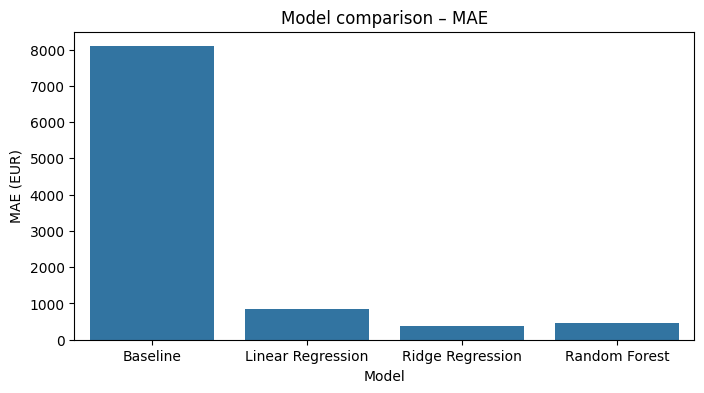

In [17]:
# Comparing model errors

plt.figure(figsize=(8, 4))

sns.barplot(data=comparison, x="Model", y="MAE (EUR)")

plt.title("Model comparison – MAE")
plt.ylabel("MAE (EUR)")
plt.xlabel("Model")
plt.show()

All three regression models performed much better than the baseline model.

Ridge Regression achieved the lowest MAE of 377,28 EUR, followed by Random Forest with 464,74 EUR and Linear Regression with 850,08 EUR. The baseline MAE was 8.086,50 EUR.

Ridge Regression also achieved the lowest RMSE and the highest R² of 0,9900.

Based on the test results, Ridge Regression is currently the best-performing model. However, further analysis is needed to check for overfitting and understand prediction errors across different price ranges.

### Overfitting check

I will compare the MAE on training and test data for Linear Regression and Ridge Regression.

A much lower training error than test error may indicate overfitting.

In [18]:
# Comparing training and test errors

linear_train_mae = mean_absolute_error(
    y_train, linear_model.predict(X_train))

ridge_train_mae = mean_absolute_error(
    y_train, ridge_model.predict(X_train))

print("Linear Regression - Train MAE:", round(linear_train_mae, 2))
print("Linear Regression - Test MAE:", round(linear_mae, 2))

print("Ridge Regression - Train MAE:", round(ridge_train_mae, 2))
print("Ridge Regression - Test MAE:", round(ridge_mae, 2))

Linear Regression - Train MAE: 32.22
Linear Regression - Test MAE: 850.08
Ridge Regression - Train MAE: 266.63
Ridge Regression - Test MAE: 377.28


Linear Regression achieved a training MAE of 32,22 EUR and a test MAE of 850,08 EUR. The large difference suggests strong overfitting.

Ridge Regression achieved a training MAE of 266,63 EUR and a test MAE of 377,28 EUR, showing a smaller difference between training and test errors.

Random Forest achieved a training MAE of 437,38 EUR and a test MAE of 464,74 EUR, with no strong indication of overfitting based on these results.

Ridge Regression currently provides the best balance of low test error and generalization among the evaluated models. However, further error analysis is needed before selecting the final model.

## 9. Error analysis

I will analyze the prediction errors of Ridge Regression, which currently has the lowest MAE on the test data.

I will compare the actual reference prices with the predicted prices and calculate the error for each test record.

This will help me understand where the model makes larger prediction errors.

In [19]:
# Analyzing Ridge Regression prediction errors

error_analysis = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": ridge_predictions})

error_analysis["Error (EUR)"] = (
    error_analysis["Predicted Price"] - error_analysis["Actual Price"])

error_analysis["Absolute Error (EUR)"] = (
    error_analysis["Error (EUR)"].abs())

error_analysis.head(10).round(2)

,Actual Price,Predicted Price,Error (EUR),Absolute Error (EUR)
0,627.82,566.33,-61.49,61.49
1,1427.63,1750.69,323.06,323.06
2,1621.54,1400.13,-221.41,221.41
3,1443.61,1492.43,48.82,48.82
4,855.00,870.21,15.21,15.21
5,21549.00,21687.17,138.17,138.17
11,6775.23,7048.90,273.67,273.67
12,29852.59,31454.35,1601.76,1601.76
62,12250.00,10643.36,-1606.64,1606.64
63,45640.00,46169.01,529.01,529.01


### Percentage error

Since mechanization prices vary significantly, I will also calculate the absolute percentage error for each prediction.

This will help me compare prediction accuracy across different price ranges.

In [20]:
# Calculating absolute percentage error

error_analysis["Percentage Error (%)"] = (
    error_analysis["Absolute Error (EUR)"]
    / error_analysis["Actual Price"] * 100)

error_analysis.head(10).round(2)

,Actual Price,Predicted Price,Error (EUR),Absolute Error (EUR),Percentage Error (%)
0,627.82,566.33,-61.49,61.49,9.79
1,1427.63,1750.69,323.06,323.06,22.63
2,1621.54,1400.13,-221.41,221.41,13.65
3,1443.61,1492.43,48.82,48.82,3.38
4,855.00,870.21,15.21,15.21,1.78
5,21549.00,21687.17,138.17,138.17,0.64
11,6775.23,7048.90,273.67,273.67,4.04
12,29852.59,31454.35,1601.76,1601.76,5.37
62,12250.00,10643.36,-1606.64,1606.64,13.12
63,45640.00,46169.01,529.01,529.01,1.16


### Error analysis by price range

I will analyze prediction errors across different price ranges to understand whether the model performs equally well for lower-priced and higher-priced mechanization.

I will use the farmer's quoted price to define price categories, since this information is available when a new application is submitted.

In [21]:
# Adding farmer's quoted prices to error analysis

error_analysis["Quoted Price"] = X_test["Applicant Quoted Price (EUR)"]

error_analysis.head(10).round(2)

,Actual Price,Predicted Price,Error (EUR),Absolute Error (EUR),Percentage Error (%),Quoted Price
0,627.82,566.33,-61.49,61.49,9.79,595.04
1,1427.63,1750.69,323.06,323.06,22.63,1735.53
2,1621.54,1400.13,-221.41,221.41,13.65,1611.57
3,1443.61,1492.43,48.82,48.82,3.38,1446.28
4,855.00,870.21,15.21,15.21,1.78,979.33
5,21549.00,21687.17,138.17,138.17,0.64,23347.93
11,6775.23,7048.90,273.67,273.67,4.04,6809.00
12,29852.59,31454.35,1601.76,1601.76,5.37,31692.00
62,12250.00,10643.36,-1606.64,1606.64,13.12,13400.00
63,45640.00,46169.01,529.01,529.01,1.16,51150.00


In [22]:
# Now I want to explore the distribution of quoted prices

error_analysis["Quoted Price"].describe().round(2)

,Quoted Price
count,694.00
mean,7939.84
std,12537.85
min,53.71
25%,1250.00
50%,2717.24
75%,8400.00
max,117240.00


I will divide the test data into two price categories based on the median quoted price: lower-priced and higher-priced mechanization.

This will help me compare prediction errors across different price ranges.

In [23]:
# Dividing quoted prices into two categories

error_analysis["Price Category"] = np.where(
    error_analysis["Quoted Price"] <= 2717.24,
    "Lower-priced",
    "Higher-priced")

error_analysis["Price Category"].value_counts()

,count
Price Category,
Lower-priced,349
Higher-priced,345


### Prediction errors by price category

The test data was divided into two groups based on the median quoted price of 2.717,24 EUR.

I will compare the average absolute error in EUR and the average percentage error for both groups to see whether Ridge Regression performs differently across price ranges.

In [24]:
# Comparing prediction errors by price category

category_errors = error_analysis.groupby("Price Category")[
    ["Absolute Error (EUR)", "Percentage Error (%)"]].mean()

category_errors.round(2)

,Absolute Error (EUR),Percentage Error (%)
Price Category,,
Higher-priced,641.66,5.72
Lower-priced,115.93,14.72


### Error analysis by price category – findings

For lower-priced mechanization, Ridge Regression achieved an average absolute error of 115,93 EUR and an average percentage error of 14,72%.

For higher-priced mechanization, the average absolute error was 641,66 EUR, while the average percentage error was only 5,72%.

These results suggest that Ridge Regression has higher relative prediction errors for lower-priced mechanization.

However, further analysis is needed to identify large individual errors and evaluate whether the model can reliably support price assessment decisions.

### Large prediction errors

I will check how many predictions have an absolute percentage error greater than 30% in each price category.

This will help me identify where the model makes large prediction errors.

In [25]:
# Identifing prediction errors greater than 30%

error_analysis["Large Error"] = np.where(
    error_analysis["Percentage Error (%)"] > 30, 1, 0)

error_analysis.groupby("Price Category")["Large Error"].agg(["sum", "count"])

,sum,count
Price Category,,
Higher-priced,12,345
Lower-priced,42,349


Out of 694 test records, 54 predictions (7,8%) had an absolute percentage error greater than 30%.

For lower-priced mechanization, 42 out of 349 predictions (12,0%) exceeded this threshold, compared with 12 out of 345 (3,5%) for higher-priced mechanization.

These results show that Ridge Regression makes large relative errors more frequently for lower-priced equipment.

However, prediction error alone does not determine whether an farmer's quoted price is acceptable.

### Price deviation analysis

I will compare the farmer's quoted price with both the actual and predicted reference prices.

This will help me evaluate whether Ridge Regression can correctly identify quoted prices that fall within the ±30% range.

In [26]:
# Calculating actual and predicted price deviations

error_analysis["Actual Deviation (%)"] = (
    (error_analysis["Quoted Price"] - error_analysis["Actual Price"])
    / error_analysis["Actual Price"] * 100)

error_analysis["Predicted Deviation (%)"] = (
    (error_analysis["Quoted Price"] - error_analysis["Predicted Price"])
    / error_analysis["Predicted Price"] * 100)

error_analysis[[
    "Quoted Price",
    "Actual Price",
    "Predicted Price",
    "Actual Deviation (%)",
    "Predicted Deviation (%)"]].head(10).round(2)

,Quoted Price,Actual Price,Predicted Price,Actual Deviation (%),Predicted Deviation (%)
0,595.04,627.82,566.33,-5.22,5.07
1,1735.53,1427.63,1750.69,21.57,-0.87
2,1611.57,1621.54,1400.13,-0.61,15.10
3,1446.28,1443.61,1492.43,0.18,-3.09
4,979.33,855.00,870.21,14.54,12.54
5,23347.93,21549.00,21687.17,8.35,7.66
11,6809.00,6775.23,7048.90,0.50,-3.40
12,31692.00,29852.59,31454.35,6.16,0.76
62,13400.00,12250.00,10643.36,9.39,25.90
63,51150.00,45640.00,46169.01,12.07,10.79


### Price deviation classification

I will classify quoted prices as within or outside the ±30% range using both actual and predicted reference prices.

I will then compare the two classifications to evaluate whether the model correctly identifies price deviations.

In [27]:
# Classifying prices using the 30% threshold

error_analysis["Actual Within 30%"] = (
    error_analysis["Actual Deviation (%)"].abs() <= 30)

error_analysis["Predicted Within 30%"] = (
    (error_analysis["Predicted Price"] > 0) &
    (error_analysis["Predicted Deviation (%)"].abs() <= 30))

pd.crosstab(
    error_analysis["Actual Within 30%"],
    error_analysis["Predicted Within 30%"])


Predicted Within 30%,False,True
Actual Within 30%,,
False,77,43
True,36,538


Ridge Regression correctly classified 615 out of 694 test records (88,6%) as within or outside the ±30% price deviation range.

However, 43 out of 120 records that were actually outside the ±30% range were incorrectly classified as within the range.

This is an important limitation because the model could incorrectly accept unrealistic quoted prices.

Although Ridge Regression achieved strong regression metrics, these results show that further evaluation is needed before using it to support price assessment decisions.

In [28]:
# Checking for invalid predicted prices

invalid_prices = (error_analysis["Predicted Price"] <= 0).sum()

print("Invalid predicted prices:", invalid_prices)

Invalid predicted prices: 2


In [29]:
# Now I wnat to see invalid predicted prices

error_analysis[
    error_analysis["Predicted Price"] <= 0
][["Quoted Price", "Actual Price", "Predicted Price"]].round(2)

,Quoted Price,Actual Price,Predicted Price
411,484.30,831.4,-414.22
412,427.27,750.0,-465.60


Ridge Regression produced two negative reference price predictions out of 694 test records.

Both records were outside the actual ±30% deviation range. Negative predicted prices are not valid and should be referred for manual price verification.

The classification results remained unchanged after excluding these predictions from automatic acceptance.

## 10. Interpretation

### Interpretation of results

Three regression models were evaluated to predict agricultural mechanization reference prices using equipment type, manufacturer, model specifications and the farmer's quoted price.

Ridge Regression achieved the best overall performance, with an MAE of 377,28 EUR and an R² of 0,9900.

However, the error analysis showed that the model performs differently across price ranges. The average percentage error was 14,72% for lower-priced mechanization and 5,72% for higher-priced mechanization.

When evaluating the ±30% price deviation threshold, the model correctly classified 615 out of 694 test records (88,6%). However, 43 records outside the acceptable range were incorrectly classified as within the range.

These findings suggest that Ridge Regression could support price assessment, but its predictions are not sufficiently reliable for fully automated decisions. Additional manual verification would still be necessary for uncertain cases.

## 11. Limitations & ethics

The dataset contains historical agricultural mechanization prices, which may not fully reflect current regional market conditions.

The model uses the farmer's quoted price as an input feature. This may influence the predicted reference price, especially when the quoted price is unrealistic.

Although Ridge Regression achieved strong regression results, the error analysis showed that it can incorrectly classify prices outside the ±30% range as acceptable.

The model also showed higher relative errors for lower-priced mechanization and produced two negative price predictions.

For these reasons, the model should be used as a decision-support tool rather than a replacement for the Evaluation Committee. Human verification remains important to reduce the risk of incorrect decisions.

## 12. Conclusion & next steps

The goal of this project was to explore whether machine learning can help determine if a quoted agricultural mechanization price is within ±30% of a reasonable regional reference price.

Three regression models were tested: Linear Regression, Ridge Regression, and Random Forest. Ridge Regression achieved the best overall performance, with an MAE of 377,28 EUR and an R² of 0,9900.

However, the error analysis showed that good regression performance does not always lead to correct price deviation classifications. The model correctly classified 88,6% of test records, but incorrectly identified 43 prices outside the ±30% range as being within it.

The results also showed higher relative prediction errors for lower-priced mechanization.

These findings suggest that machine learning has potential to support the price evaluation process, but the current model is not reliable enough for fully automated decisions.

As a next step, the model could be improved and tested further to identify cases where predictions are sufficiently reliable, while uncertain cases would still require manual verification.

The long-term objective is to reduce manual workload and speed up the evaluation process while maintaining reliable price assessments.